# CGCNN: a faithful re-implementation, and does a graph network do better on unfamiliar materials?

The crystal graph convolutional neural network (CGCNN; Xie & Grossman, Phys. Rev. Lett. 120, 145301, 2018) was the first network to learn material properties directly from the graph of atoms and their neighbors in a crystal. It is small (about 81 000 weights), still a common baseline, and the ancestor of most later crystal graph networks. This notebook asks three questions:

1. **Is this the original?** `materials_ml_primer.cgcnn` re-implements the authors' released code. With the same weights it must give the same outputs as their code, and its graphs must be the ones their code builds (verification).
2. **Does it reproduce the published accuracy?** On the formation-energy split of the JARVIS leaderboard, the authors' code reaches a test MAE of 0.0625 eV/atom (validation).
3. **Is it better than gradient boosting where it matters?** The `data_splits` experiment found that gradient boosting on 150 descriptors loses accuracy on new chemical systems, new structure types, unseen elements and materials computed later, and the `uncertainty` experiment found that no uncertainty method fully warns of this. Here an ensemble of five CGCNNs is trained on exactly the same training, validation, calibration and test sets, to see whether a network that reads the structure itself generalizes better, and whether its ensemble knows when it is wrong.

The released code differs from the equations of the paper; the code is followed here because the published benchmark numbers come from it:

| | Paper (Eq. 5, Supplemental Material) | Released code (commit f42ab23), followed here |
|---|---|---|
| convolution | v_i + Σ_j σ(z_ij W_f + b_f) ⊙ g(z_ij W_s + b_s) | softplus(v_i + BN(Σ_j σ(f_ij) ⊙ softplus(c_ij))), (f_ij, c_ij) = BN(z_ij W + b) |
| neighbors | Voronoi faces and covalent radii; "12 nearest neighbors performs as good" | the 12 nearest within 8 Å |
| edge features | one-hot distance in 10 bins, 0.7–5.2 Å | 41 Gaussians, centers 0–8 Å, width 0.2 Å |
| atom features | 9 properties, one-hot | the 92-dimensional table `atom_init.json` |
| optimizer | Adam, tuned step size | SGD, learning rate 0.01, momentum 0.9 (default) |

In [1]:
import importlib.util
import io
import json
import subprocess
import sys
import time
import urllib.request
import warnings
import zipfile
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import stats

import runs
from materials_ml_primer import cgcnn, data
from materials_ml_primer import uncertainty as uq

QUICK = False       # True only in a test run of this notebook: use the cached networks, train nothing
ALPHA = 0.1           # 90 % intervals
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SPLITS = ["random", "chemical-system groups", "prototype groups", "leave one element out", "prospective"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10})
summary = []          # rows of the summary table: (quantity, this run, check, check from)
print(f"torch {torch.__version__}, device {torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'cpu'}")

torch 2.15.0+cu132, device NVIDIA GeForce RTX 3060


In [2]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", "--color=no", "-p", "no:cacheprovider",
                    "../../tests/test_cgcnn.py"], capture_output=True, text=True)
print(r.stdout[-1500:])

..........                                                               [100%]
10 passed in 8.41s



The tests check the parts one at a time: the neighbor lists against the lines of the original's `CIFData` that build them (CsCl, where the 8 + 6 nearest neighbors are cut at 12, rock salt and two random cells), the padding of an atom with no neighbors within 8 Å, batching, one convolution against the formula written out atom by atom, the invariance of a prediction to the order of the atoms, a rotation and the choice of the unit cell (a supercell), and training that overfits one batch.

## 1. Data

In [3]:
t0 = time.perf_counter()
d = runs.load()
n_atoms = d["graphs"].n_atoms.numpy()
print(f"{len(d['y'])} materials of JARVIS-DFT 2021.8.18 and {len(d['y_add'])} added up to 2025.9.24 "
      f"({time.perf_counter() - t0:.0f} s, graphs cached in data/cgcnn_cache)")
print(f"atoms per structure: median {np.median(n_atoms):.0f}, mean {n_atoms.mean():.1f}, max {n_atoms.max()}; "
      f"{n_atoms.sum()} atoms with 12 neighbors each")
pad = d["padded_per_crystal"]
print(f"structures with an atom that has fewer than 12 neighbors within 8 Å: {np.sum(pad > 0)} "
      f"({pad.sum()} padding entries of {12 * n_atoms.sum()}); added materials: {d['padded_add']} entries")

55712 materials of JARVIS-DFT 2021.8.18 and 38190 added up to 2025.9.24 (7 s, graphs cached in data/cgcnn_cache)
atoms per structure: median 6, mean 10.1, max 140; 562055 atoms with 12 neighbors each
structures with an atom that has fewer than 12 neighbors within 8 Å: 161 (3528 padding entries of 6744660); added materials: 378 entries


## 2. Verification: the original code with the same weights

The authors' `model.py` and `data.py` are downloaded at the pinned commit (into `data/`, not committed) and imported. The state dict of a freshly initialized network of this package is loaded into the original network, and both predict the same 300 crystals. The only difference between the two is the pooling: the original loops over crystals in Python, this package sums with `index_add`. In training mode the batch-norm layers use the batch statistics, in evaluation mode the running ones, so both modes are compared.

In [4]:
ORIGINAL = "https://raw.githubusercontent.com/txie-93/cgcnn/f42ab233c4ee0c416879d6bc2d22a264418413ad/"
orig_dir = runs.DATA_DIR / "cgcnn_original"
orig_dir.mkdir(parents=True, exist_ok=True)
for f in ("cgcnn/model.py", "cgcnn/data.py", "data/sample-regression/atom_init.json"):
    if not (orig_dir / f.split("/")[-1]).exists():
        urllib.request.urlretrieve(ORIGINAL + f, orig_dir / f.split("/")[-1])


def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


orig_model = import_file("cgcnn_original_model", orig_dir / "model.py")
orig_data = import_file("cgcnn_original_data", orig_dir / "data.py")
same_table = json.loads((orig_dir / "atom_init.json").read_text()) == json.loads(cgcnn.ATOM_INIT.read_text())
print(f"vendored atom_init.json identical to the original's: {same_table}")

graphs = d["graphs"].to(DEVICE)
featurizer = cgcnn.Featurizer(DEVICE)
torch.manual_seed(0)
mine = cgcnn.CrystalGraphConvNet().to(DEVICE)
theirs = orig_model.CrystalGraphConvNet(92, 41).to(DEVICE)
theirs.load_state_dict(mine.state_dict())
print(f"weights: {sum(p.numel() for p in mine.parameters())}")
atom_fea, edge_fea, nbr_idx, owner, n_c = featurizer(graphs, np.arange(300))
crystal_atom_idx = [torch.nonzero(owner == c).view(-1) for c in range(n_c)]
for mode in ("train", "eval"):
    mine.train(mode == "train")
    theirs.train(mode == "train")
    with torch.no_grad():
        a = mine(atom_fea, edge_fea, nbr_idx, owner, n_c)
        b = theirs(atom_fea, edge_fea, nbr_idx, crystal_atom_idx)
    diff = float((a - b).abs().max())
    print(f"{mode} mode: largest difference of the 300 outputs {diff:.1e} (outputs up to {float(b.abs().max()):.2f})")
    summary.append((f"same weights as the original code, {mode} mode: largest output difference", f"{diff:.0e}",
                    "0 up to float32 rounding", "txie-93/cgcnn f42ab23"))

vendored atom_init.json identical to the original's: True
weights: 80833


train mode: largest difference of the 300 outputs 2.4e-07 (outputs up to 1.70)
eval mode: largest difference of the 300 outputs 1.5e-06 (outputs up to 1.93)


### The graphs the original builds

The original reads a CIF file with pymatgen, calls `Structure.get_all_neighbors(8)` and sorts each atom's neighbors by distance. Two checks:

- the original's lines on the JARVIS structures themselves (2000 structures), against `cgcnn.crystal_graph`: the neighbor indices and distances must be identical, including which of several equally distant neighbors takes the twelfth place;
- the path of the leaderboard run: CIF files written by jarvis-tools and read by the original `CIFData` (300 random structures). A CIF stores cell lengths and angles, so the cell is rotated, and coordinates with a finite number of digits, so atoms move slightly; pymatgen may also reorder the atoms. The comparison therefore matches the atoms first.

In [5]:
from pymatgen.core import Lattice, Structure

same = 0
for rec in d["records"][:2000]:
    lat, frac, sp = data.structure_arrays(rec["atoms"])
    s = Structure(Lattice(lat), sp, frac)
    nbrs = [sorted(n, key=lambda x: x[1]) for n in s.get_all_neighbors(8.0, include_index=True)]
    idx = np.array([[x[2] for x in n[:12]] + [0] * (12 - len(n[:12])) for n in nbrs])
    dist = np.array([[x[1] for x in n[:12]] + [9.0] * (12 - len(n[:12])) for n in nbrs])
    _, mi, md_, _ = cgcnn.crystal_graph(lat, frac, sp)
    same += bool(np.array_equal(idx, mi) and np.array_equal(dist, md_))
print(f"original construction on the JARVIS structures: identical neighbors and distances in {same} of 2000")
summary.append(("neighbor lists identical to the original construction", f"{same} / 2000", "2000 / 2000",
                "Structure.get_all_neighbors + sort"))

original construction on the JARVIS structures: identical neighbors and distances in 2000 of 2000


In [6]:
from jarvis.core.atoms import Atoms

rng = np.random.default_rng(0)
pick = rng.choice(len(d["records"]), 300, replace=False)
work = runs.DATA_DIR / "cgcnn_original" / "cifs"
work.mkdir(parents=True, exist_ok=True)
(work / "atom_init.json").write_text((orig_dir / "atom_init.json").read_text())
jid = [rec["jid"] for rec in d["records"]]
with open(work / "id_prop.csv", "w") as f:
    for i in pick:
        f.write(f"{jid[i]},{d['y'][i]}\n")
        Atoms.from_dict(d["records"][i]["atoms"]).write_cif(str(work / f"{jid[i]}.cif"))
table = cgcnn.atom_feature_table()
reordered, worst_move, worst_dist, worst_feat, same_species = 0, 0.0, 0.0, 0.0, 0
with warnings.catch_warnings():
    warnings.simplefilter("ignore")          # pymatgen reports rounded CIF coordinates
    ds = orig_data.CIFData(str(work))
    for k in range(len(ds)):
        (a_fea, n_fea, n_idx), _, cid = ds[k]
        i = jid.index(cid)
        lat, frac, sp = data.structure_arrays(d["records"][i]["atoms"])
        direct = Structure(Lattice(lat), sp, frac)
        parsed = Structure.from_file(str(work / f"{cid}.cif"))
        perm, moves = [], []
        for site in parsed:
            dd = [direct.lattice.get_distance_and_image(site.frac_coords, s.frac_coords)[0]
                  if s.specie == site.specie else np.inf for s in direct]
            perm.append(int(np.argmin(dd)))
            moves.append(min(dd))
        perm = np.array(perm)
        assert len(set(perm)) == len(perm)
        reordered += not np.array_equal(perm, np.arange(len(perm)))
        worst_move = max(worst_move, max(moves))
        numbers, _, dist, _ = cgcnn.crystal_graph(lat, frac, sp)
        same_species += np.array_equal(a_fea.numpy(), table[numbers[perm]])
        ref = np.exp(-((dist[perm][..., None] - cgcnn.gaussian_centers()) / 0.2) ** 2)
        worst_feat = max(worst_feat, float(np.abs(n_fea.numpy() - ref).max()))
        parsed_dist = cgcnn.crystal_graph(parsed.lattice.matrix, parsed.frac_coords,
                                          [s.specie.symbol for s in parsed])[2]
        worst_dist = max(worst_dist, float(np.abs(parsed_dist - dist[perm]).max()))
print(f"CIF path, 300 structures: atoms reordered by the CIF reader in {reordered}; largest displacement of an atom "
      f"{worst_move:.1e} Å; atom features identical after matching the atoms: {same_species}")
print(f"  after matching: largest difference of a neighbor distance {worst_dist:.1e} Å, of an edge feature "
      f"{worst_feat:.1e}")

CIF path, 300 structures: atoms reordered by the CIF reader in 48; largest displacement of an atom 6.3e-04 Å; atom features identical after matching the atoms: 300
  after matching: largest difference of a neighbor distance 6.0e-04 Å, of an edge feature 2.5e-03


The CIF path changes the input only by the rounding of the coordinates in the CIF file (well below 10⁻³ Å) and by the order of the atoms, which the network does not see. So training on the JARVIS structures directly, as here, is training on the leaderboard's graphs.

## 3. Validation: the JARVIS leaderboard

The JARVIS leaderboard (Choudhary et al., npj Comput. Mater., 2024) holds a CGCNN entry for the formation energy of `dft_3d_2021`: its run script trains the original code for 300 epochs with batches of 256 crystals and learning rate 0.01, and its test predictions give an MAE of 0.0625 eV/atom (the ALIGNN paper, Choudhary & DeCost, npj Comput. Mater. 7, 185, 2021, Table 3, lists 0.063 for CGCNN on the same data). Its split file has 44 569 training, 5 572 validation and 5 572 test materials. Two materials are in both its training and its test set (their records are repeated in `dft_3d_2021`); they stay in the test set and are removed from the training set here.

Five networks with seeds 0–4 are trained with the original's procedure (see the module docstring), with one change: the original standardizes the targets with the mean and standard deviation of 500 random materials of the whole data set, test set included; here the 500 materials are drawn from the training set. Expected before training: a validation MAE of 0.06–0.07 eV/atom, as for the leaderboard, with the training loss (normalized mean squared error) below the validation error, and most of the improvement after the learning-rate drop at epoch 100 coming within some tens of epochs.

In [7]:
lb_task = runs.tasks(d, "leaderboard")[0]
lb_split = runs.leaderboard_split(d)
lb = []
for seed in range(runs.MEMBERS):
    res = runs.result(d, "leaderboard", lb_task, seed, compute=not QUICK, device=DEVICE)
    if res is not None:
        lb.append(res[0])
y_test = d["y"][lb_task[4]]
board = pd.read_csv(io.BytesIO(runs.leaderboard_file("cgcnn")))
pos = {j: i for i, j in enumerate(jid)}
board_pred = pd.Series(board.prediction.values, index=[pos[j] for j in board.id]).loc[lb_task[4]].values
board_mae = np.mean(np.abs(board_pred - y_test))
print(f"leaderboard test set: {len(y_test)} materials; dropped from training: {[jid[i] for i in lb_split['dropped']]}")
print(f"{'seed':>4s} {'best epoch':>10s} {'validation MAE':>15s} {'test MAE':>9s} {'minutes':>8s}")
for seed, r in enumerate(lb):
    print(f"{seed:4d} {int(r['best_epoch']):10d} {r['val_mae'].min():15.4f} {np.mean(np.abs(r['test_pred'] - y_test)):9.4f} "
          f"{float(r['seconds']) / 60:8.1f}")
single = np.array([np.mean(np.abs(r["test_pred"] - y_test)) for r in lb])
ens_pred = np.mean([r["test_pred"] for r in lb], axis=0)
ens_mae = np.mean(np.abs(ens_pred - y_test))
print(f"single networks: test MAE {single.mean():.4f} ± {single.std(ddof=1):.4f} (mean ± sd of {len(lb)} seeds)")
print(f"ensemble of {len(lb)}: test MAE {ens_mae:.4f}; the leaderboard's CGCNN on the same materials: {board_mae:.4f}")
# paired comparison with the leaderboard predictions, material by material
diff = np.abs(lb[0]["test_pred"] - y_test) - np.abs(board_pred - y_test)
boot = np.random.default_rng(0).choice(len(diff), (2000, len(diff)))
lo, hi = np.percentile(diff[boot].mean(axis=1), [2.5, 97.5])
print(f"seed 0 minus leaderboard, MAE difference {diff.mean():+.4f} eV/atom (95 % bootstrap interval {lo:+.4f} to {hi:+.4f})")
print(f"correlation of the errors of seed 0 and of the leaderboard: "
      f"{np.corrcoef(lb[0]['test_pred'] - y_test, board_pred - y_test)[0, 1]:.3f}; between two of our seeds: "
      f"{np.corrcoef(lb[0]['test_pred'] - y_test, lb[1]['test_pred'] - y_test)[0, 1]:.3f}")
summary.append(("test MAE, leaderboard split, single network (5 seeds)", f"{single.mean():.4f} ± {single.std(ddof=1):.4f}",
                f"{board_mae:.4f}", "JARVIS leaderboard, CGCNN entry"))
summary.append(("test MAE, leaderboard split, ensemble of 5", f"{ens_mae:.4f}", "0.063", "Choudhary & DeCost 2021, Table 3"))

leaderboard test set: 5572 materials; dropped from training: ['JVASP-113961', 'JVASP-116461']
seed best epoch  validation MAE  test MAE  minutes
   0        275          0.0638    0.0656     22.7
   1        287          0.0619    0.0627     23.2
   2        273          0.0624    0.0638     23.3
   3        297          0.0613    0.0635     16.1
   4        297          0.0626    0.0651     15.6
single networks: test MAE 0.0641 ± 0.0012 (mean ± sd of 5 seeds)
ensemble of 5: test MAE 0.0548; the leaderboard's CGCNN on the same materials: 0.0625


seed 0 minus leaderboard, MAE difference +0.0031 eV/atom (95 % bootstrap interval +0.0015 to +0.0048)
correlation of the errors of seed 0 and of the leaderboard: 0.749; between two of our seeds: 0.743


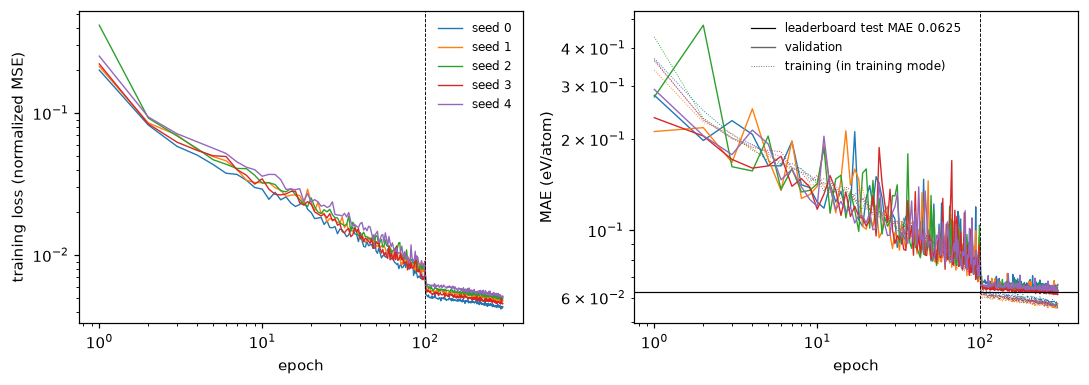

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
epochs = np.arange(1, len(lb[0]["val_mae"]) + 1) if lb else np.arange(1)
for seed, r in enumerate(lb):
    axes[0].loglog(epochs, r["train_loss"], color=f"C{seed}", lw=0.9, label=f"seed {seed}")
    axes[1].loglog(epochs, r["train_mae"], color=f"C{seed}", lw=0.6, ls=":")
    axes[1].loglog(epochs, r["val_mae"], color=f"C{seed}", lw=0.9)
for ax in axes:
    ax.axvline(runs.SETTINGS["leaderboard"]["milestones"][0], color="k", lw=0.6, ls="--")
    ax.set_xlabel("epoch")
axes[1].axhline(board_mae, color="k", lw=0.8, label=f"leaderboard test MAE {board_mae:.4f}")
axes[0].set_ylabel("training loss (normalized MSE)")
axes[1].set_ylabel("MAE (eV/atom)")
axes[1].plot([], [], color="0.4", lw=0.9, label="validation")
axes[1].plot([], [], color="0.4", lw=0.6, ls=":", label="training (in training mode)")
axes[0].legend(frameon=False, fontsize=8)
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("figures/learning_curves.png")
plt.show()

### How many epochs are needed?

Training 215 more networks for 300 epochs each would take more than a day on this GPU. Every time the validation MAE of a run reached a new minimum, the test MAE was recorded, so the result of stopping after fewer epochs (keeping the best validation epoch so far, as the original does) can be read off the same five runs. The decision for the networks of the next sections is made on the validation MAE; the test MAE is shown for information.

In [9]:
budgets = [50, 100, 110, 125, 150, 200, 250, 300]
print(f"{'epochs':>6s} {'best validation MAE':>20s} {'test MAE at that epoch':>23s} {'test MAE / 300 epochs':>22s}")
budget_rows = []
for e in budgets:
    v, t = [], []
    for r in lb:
        best = int(np.argmin(r["val_mae"][:e]))
        v.append(r["val_mae"][best])
        k = np.searchsorted(r["track_epoch"], best, side="right") - 1
        t.append(r["track_mae"][k])
    budget_rows.append((e, np.mean(v), np.mean(t)))
for e, v, t in budget_rows:
    print(f"{e:6d} {v:20.4f} {t:23.4f} {t / budget_rows[-1][2]:22.3f}")

epochs  best validation MAE  test MAE at that epoch  test MAE / 300 epochs
    50               0.0814                  0.0830                  1.294
   100               0.0695                  0.0716                  1.117
   110               0.0648                  0.0664                  1.035
   125               0.0643                  0.0662                  1.031
   150               0.0640                  0.0657                  1.025
   200               0.0634                  0.0650                  1.014
   250               0.0629                  0.0645                  1.005
   300               0.0624                  0.0641                  1.000


The best validation epoch of all five runs is late (above 270): the networks still improve slowly at 300 epochs. Most of the gain from the learning-rate drop at epoch 100 comes within ten epochs, though, and stopping at 150 epochs raises the validation MAE by about 2.6 % (and the test MAE by about as much). That is small next to the differences between splits that the next sections measure (gradient boosting lost 27 % on new chemical systems and 90 % on new structure types in `data_splits`), so the networks of sections 4 and 5 are trained for **150 epochs**, with the learning rate dropped at epoch 100 as before, which halves the computing time. This is a departure from the leaderboard run, and their accuracy is about 2–3 % worse than that of a 300-epoch network.

Whether stopping early costs as little under distribution shift is checked on three of those tasks (the first chemical-system and prototype folds and leave-F-out): one network each is trained for the full 300 epochs, and the tracked test MAE is read off at 150 and at 300 epochs. The shift network with the same seed was trained identically for its 150 epochs, so its test MAE should match the 300-epoch run at epoch 150, up to the run-to-run variation of GPU arithmetic (atomic additions in an unspecified order).

In [10]:
shift_by_key = {t[0]: t for t in runs.tasks(d, "shift")}
print(f"{'task':12s} {'val MAE 150':>12s} {'val MAE 300':>12s} {'test MAE 150':>13s} {'test MAE 300':>13s} "
      f"{'300 / 150':>10s} {'shift network (150), test':>26s}")
for task in runs.tasks(d, "budget"):
    res = runs.result(d, "budget", task, 0, compute=not QUICK, device=DEVICE)
    if res is None:
        continue
    r, key = res[0], task[0].removeprefix("budget-")
    vals, tests = [], []
    for e in (150, 300):
        best = int(np.argmin(r["val_mae"][:e]))
        vals.append(r["val_mae"][best])
        tests.append(r["track_mae"][np.searchsorted(r["track_epoch"], best, side="right") - 1])
    twin = runs.result(d, "shift", shift_by_key[key], 0, compute=False)
    y_t = (d["y_add"] if task[5] else d["y"])[task[4]]
    twin_mae = f"{np.mean(np.abs(twin[0]['test_pred'] - y_t)):26.4f}" if twin else f"{'not trained yet':>26s}"
    print(f"{key:12s} {vals[0]:12.4f} {vals[1]:12.4f} {tests[0]:13.4f} {tests[1]:13.4f} {tests[1] / tests[0]:10.3f} {twin_mae}")

task          val MAE 150  val MAE 300  test MAE 150  test MAE 300  300 / 150  shift network (150), test


chemical-0         0.0729       0.0714        0.0744        0.0731      0.983                     0.0744
prototype-0        0.1084       0.1043        0.0771        0.0721      0.935                     0.0771
element-F          0.0676       0.0664        1.5042        1.5137      1.006                     1.5042


## 4. Distribution shift: CGCNN and gradient boosting on the same test sets

The tasks are those of the `uncertainty` experiment, with the same materials in every part: the 10 folds of the random, chemical-system and prototype splits (fold k test, k + 1 validation, k + 2 calibration, the other seven training), the prospective test (trained on the 2021 snapshot, tested on the 38 190 materials added up to 2025.9.24), and leave one element out for 12 elements: the six whose compounds gradient boosting predicted worst in `data_splits` (F, N, H, O, Be, C, also the hardest for Li et al. 2024) and six spread over the others (the middle element of six equal parts of the other 72 ordered by R²: B, W, Bi, Ni, Zr, Tb). Each task gets five CGCNNs (seeds 0–4) trained like those of section 3 but for 150 epochs, 215 networks in all.

The comparison uses the predictions cached by the `uncertainty` experiment for the same tasks: the mean of the bootstrap ensemble of five gradient-boosting models (HGB), the random forest (RF) and the deep ensemble of five multilayer perceptrons (MLP), all on the 150 descriptors.

In [11]:
SHIFT = runs.tasks(d, "shift")
UQR = runs._uncertainty_runs()
uq_tasks = {t.key: t for t in UQR.tasks(d)}
split_of = {t.key: t.split for t in uq_tasks.values()}
counts, minutes, missing, R = Counter(), 0.0, [], {}
for task in SHIFT:
    members = []
    for seed in range(runs.MEMBERS):
        res = runs.result(d, "shift", task, seed, compute=not QUICK, device=DEVICE)
        if res is None:
            break
        members.append(res[0])
        counts[res[1]] += 1
        minutes += float(res[0]["seconds"]) / 60
    other = [UQR.result(d, uq_tasks[task[0]], part, compute=False) for part in ("cpu", "gpu")]
    if len(members) < runs.MEMBERS or any(o is None for o in other):
        missing.append(task[0])
        continue
    key, train, val, cal, test, added = task
    r = {"key": key, "split": split_of[key], "test": test, "added": added,
         "y_cal": d["y"][cal], "y_test": (d["y_add"] if added else d["y"])[test]}
    for s in ("cal", "test"):
        preds = np.array([m[f"{s}_pred"] for m in members])
        r[f"{s}_mu_cg"], r[f"{s}_sd_cg"] = preds.mean(axis=0), preds.std(axis=0, ddof=1)
        r[f"{s}_single_cg"] = preds
        for o in other:
            for k in ("mu_ens", "sd_ens", "mu_rf", "sd_rf", "mu_nn", "sd_nn"):
                if f"{s}_{k}" in o[0]:
                    r[f"{s}_{k}"] = o[0][f"{s}_{k}"]
    r["best_epochs"] = np.array([int(m["best_epoch"]) for m in members])
    R[key] = r
print(dict(counts), f"training time stored with the networks: {minutes / 60:.1f} h; tasks used: {len(R)} of {len(SHIFT)}"
      + (f"; missing: {', '.join(missing[:8])}" if missing else ""))
if R:
    be = np.concatenate([r["best_epochs"] for r in R.values()])
    print(f"best epoch of the networks: median {np.median(be):.0f}, in the last 10 epochs: "
          f"{np.mean(be >= runs.SETTINGS['shift']['epochs'] - 10):.0%}")

{'cached': 215} training time stored with the networks: 41.8 h; tasks used: 43 of 43
best epoch of the networks: median 141, in the last 10 epochs: 56%


In [12]:
MODELS = {"CGCNN (one network)": None, "CGCNN (ensemble of 5)": "mu_cg", "HGB (ensemble of 5)": "mu_ens",
          "random forest": "mu_rf", "MLP (deep ensemble)": "mu_nn"}


def mae(r, key):
    if key is None:
        return float(np.mean(np.abs(r["test_single_cg"] - r["y_test"])))
    return float(np.mean(np.abs(r[f"test_{key}"] - r["y_test"])))


mae_table = {}
print(f"{'split':24s} {'tasks':>5s} " + " ".join(f"{m:>22s}" for m in MODELS) + f" {'CGCNN better than HGB':>22s}")
for split in SPLITS:
    rs = [r for r in R.values() if r["split"] == split]
    if not rs:
        continue
    row = {m: np.array([mae(r, k) for r in rs]) for m, k in MODELS.items()}
    mae_table[split] = {m: (float(v.mean()), float(v.std(ddof=1)) if len(v) > 1 else 0.0) for m, v in row.items()}
    better = np.sum(row["CGCNN (ensemble of 5)"] < row["HGB (ensemble of 5)"])
    cells = " ".join(f"{v.mean():12.4f} ± {v.std(ddof=1) if len(v) > 1 else 0:7.4f}" for v in row.values())
    print(f"{split:24s} {len(rs):5d} {cells} {better:>14d} of {len(rs)}")
if "random" in mae_table:
    print("\nMAE relative to the random split (mean over tasks):")
    for split in mae_table:
        print(f"  {split:24s} " + "  ".join(f"{m.split(' (')[0]} {mae_table[split][m][0] / mae_table['random'][m][0]:.2f}"
                                          for m in ("CGCNN (ensemble of 5)", "HGB (ensemble of 5)")))

split                    tasks    CGCNN (one network)  CGCNN (ensemble of 5)    HGB (ensemble of 5)          random forest    MLP (deep ensemble)  CGCNN better than HGB
random                      10       0.0657 ±  0.0014       0.0563 ±  0.0015       0.0878 ±  0.0022       0.1056 ±  0.0030       0.1053 ±  0.0033             10 of 10
chemical-system groups      10       0.0723 ±  0.0015       0.0619 ±  0.0013       0.1054 ±  0.0030       0.1308 ±  0.0044       0.1211 ±  0.0035             10 of 10
prototype groups            10       0.0945 ±  0.0210       0.0837 ±  0.0213       0.1567 ±  0.0436       0.1816 ±  0.0455       0.1911 ±  0.0409             10 of 10
leave one element out       12       0.4078 ±  0.3394       0.3823 ±  0.3428       0.3032 ±  0.2213       0.3329 ±  0.2469       0.3679 ±  0.3593              2 of 12
prospective                  1       0.0835 ±  0.0000       0.0731 ±  0.0000       0.1165 ±  0.0000       0.1404 ±  0.0000       0.1323 ±  0.0000              1 of

### Leave one element out, element by element

For each held-out element: the MAE and R² of the CGCNN ensemble and of the gradient-boosting ensemble, and the R² that Li et al. (2024, arXiv:2406.06489, Supplementary Figs. 2 and 3) report for XGBoost and for ALIGNN, a more accurate crystal graph network, on JARVIS. Their numbers are context, not a check: their JARVIS snapshot is 2022.12.12 without materials above 5 eV/atom, they train on all other materials and their models differ.

In [13]:
LI2024_ALIGNN = {"H": 0.788, "Be": 0.916, "B": 0.900, "C": 0.807, "N": 0.749, "O": 0.383, "F": -0.764,
                 "Ni": 0.988, "Zr": 0.991, "Tb": 0.988, "W": 0.980, "Bi": 0.987}   # Li et al. 2024, Suppl. Fig. 3
ds_results = json.loads((runs.HERE.parent / "data_splits" / "data_splits_results.json").read_text(encoding="utf-8"))
hardest, spread = runs.chosen_elements()
el_rows = []
print(f"{'element':>7s} {'n':>6s} {'MAE CGCNN':>10s} {'MAE HGB':>8s} {'R2 CGCNN':>9s} {'R2 HGB':>7s} "
      f"{'R2 XGB (Li)':>12s} {'R2 ALIGNN (Li)':>15s} {'bias CGCNN':>11s}")
for e in hardest + spread:
    r = R.get(f"element-{e}")
    if r is None:
        continue
    y = r["y_test"]
    r2 = {k: 1 - np.sum((r[f"test_{k}"] - y) ** 2) / np.sum((y - y.mean()) ** 2) for k in ("mu_cg", "mu_ens")}
    row = (e, len(y), mae(r, "mu_cg"), mae(r, "mu_ens"), r2["mu_cg"], r2["mu_ens"], ds_results["loeo"][e]["li2024"],
           LI2024_ALIGNN[e], float(np.mean(r["test_mu_cg"] - y)))
    el_rows.append(row)
    print(f"{row[0]:>7s} {row[1]:6d} {row[2]:10.3f} {row[3]:8.3f} {row[4]:9.3f} {row[5]:7.3f} {row[6]:12.3f} {row[7]:15.3f} "
          f"{row[8]:+11.3f}")
if len(el_rows) > 3:
    rho_alignn = stats.spearmanr([r[4] for r in el_rows], [r[7] for r in el_rows]).statistic
    rho_hgb = stats.spearmanr([r[4] for r in el_rows], [r[5] for r in el_rows]).statistic
    print(f"Spearman over the {len(el_rows)} elements, R2 of CGCNN against: ALIGNN (Li et al.) {rho_alignn:.2f}, "
          f"HGB (this repository) {rho_hgb:.2f}")
    summary.append((f"leave one element out, Spearman of R2 over {len(el_rows)} elements", f"{rho_alignn:.2f}",
                    "ALIGNN R2 per element", "Li et al. 2024, Suppl. Fig. 3"))

element      n  MAE CGCNN  MAE HGB  R2 CGCNN  R2 HGB  R2 XGB (Li)  R2 ALIGNN (Li)  bias CGCNN
      F   3911      1.238    0.747    -1.303   0.106       -0.207          -0.764      +1.230
      N   2789      0.424    0.544     0.662   0.515        0.606           0.749      -0.330
      H   2769      0.601    0.393     0.194   0.657        0.339           0.788      +0.495
      O  14992      0.756    0.601     0.196   0.358        0.474           0.383      +0.742
     Be   4548      0.158    0.232     0.906   0.780        0.806           0.916      -0.101
      C   2812      0.392    0.276     0.709   0.795        0.789           0.807      -0.380
      B   1956      0.354    0.253     0.842   0.902        0.892           0.900      +0.247
      W   1326      0.181    0.177     0.948   0.923        0.944           0.980      +0.152
     Bi   1787      0.150    0.133     0.960   0.956        0.962           0.987      +0.135
     Ni   2697      0.106    0.098     0.971   0.968        

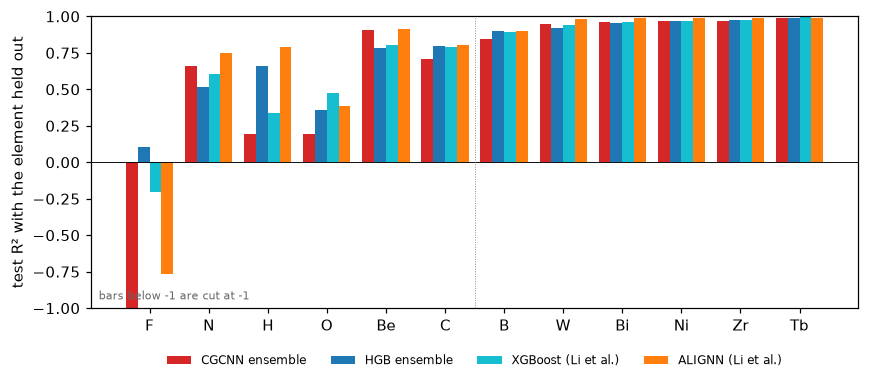

In [14]:
if el_rows:
    fig, ax = plt.subplots(figsize=(8, 3.6))
    x = np.arange(len(el_rows))
    for j, (col, label, color) in enumerate(((4, "CGCNN ensemble", "C3"), (5, "HGB ensemble", "C0"),
                                              (6, "XGBoost (Li et al.)", "C9"), (7, "ALIGNN (Li et al.)", "C1"))):
        ax.bar(x + (j - 1.5) * 0.2, [max(r[col], -1.0) for r in el_rows], width=0.2, color=color, label=label)
    ax.axhline(0, color="k", lw=0.6)
    ax.axvline(len(hardest) - 0.5, color="0.5", lw=0.6, ls=":")
    ax.set_xticks(x, [r[0] for r in el_rows])
    ax.set_ylabel("test R² with the element held out")
    ax.set_ylim(-1.0, 1.0)
    ax.text(0.01, 0.03, "bars below -1 are cut at -1", transform=ax.transAxes, fontsize=7, color="0.4")
    ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    fig.tight_layout()
    fig.savefig("figures/leave_one_element_out.png")
    plt.show()

### Columns of the atom table that training never sees

The 92 atom features are one-hot bins of nine properties; an element without a value of a property (electronegativity is missing for 15 of the 100 elements of the table, electron affinity for 26) has no bin of it. The first layer of the network multiplies these features by a weight matrix, so every column has weights of its own. If no training material contains an element in some bin, the weights of that column get no gradient and keep their random initial values, and at test time they add a random vector to the embedding of the held-out element. ALIGNN's default atom features (`atom_features="cgcnn"` in `alignn/config.py`) are the same table, as the check below confirms with jarvis-tools; Li et al. (2024) trained ALIGNN with its original settings apart from the number of layers, the batch size, the number of epochs and the normalization.

This was noticed only after the networks of this section had been trained, so the test below was added afterwards.

In [15]:
from jarvis.core.specie import get_node_attributes
from pymatgen.core import Element

BLOCKS = [("group", 0, 19), ("period", 19, 26), ("electronegativity", 26, 36), ("covalent radius", 36, 46),
          ("valence electrons", 46, 58), ("first ionization energy", 58, 68), ("electron affinity", 68, 78),
          ("block", 78, 82), ("atomic volume", 82, 92)]
table = cgcnn.atom_feature_table()
assert all(table[1:, a:b].sum(axis=1).max() == 1 for _, a, b in BLOCKS)    # at most one bin per property
same_alignn = sum(np.array_equal(np.asarray(get_node_attributes(Element.from_Z(z).symbol, atom_features="cgcnn"),
                                            dtype=float), table[z]) for z in range(1, 101))
print(f"jarvis-tools 'cgcnn' atom features (ALIGNN's default) identical to atom_init.json for {same_alignn} of 100 elements")
print("elements of the table without a value: " + ", ".join(
    f"{name} {int((table[1:, a:b].sum(axis=1) == 0).sum())}" for name, a, b in BLOCKS if (table[1:, a:b].sum(axis=1) == 0).any()))


def describe(col):
    name, a, b = next(blk for blk in BLOCKS if blk[1] <= col < blk[2])
    return f"{name}, bin {col - a + 1} of {b - a}"


unseen = {}
for e in hardest + spread:
    unseen[e] = runs.unseen_columns(d, shift_by_key[f"element-{e}"][1], e)
    print(f"{e:>3s} (R² of CGCNN {next((r[4] for r in el_rows if r[0] == e), np.nan):6.2f}): "
          + ("; ".join(f"column {c}, {describe(c)}" for c in unseen[e]) if len(unseen[e]) else "every column seen in training"))

jarvis-tools 'cgcnn' atom features (ALIGNN's default) identical to atom_init.json for 100 of 100 elements
elements of the table without a value: electronegativity 15, electron affinity 26, atomic volume 9
  F (R² of CGCNN  -1.30): column 35, electronegativity, bin 10 of 10


  N (R² of CGCNN   0.66): column 70, electron affinity, bin 3 of 10
  H (R² of CGCNN   0.19): every column seen in training


  O (R² of CGCNN   0.20): column 34, electronegativity, bin 9 of 10
 Be (R² of CGCNN   0.91): column 68, electron affinity, bin 1 of 10


  C (R² of CGCNN   0.71): every column seen in training
  B (R² of CGCNN   0.84): every column seen in training


  W (R² of CGCNN   0.95): every column seen in training
 Bi (R² of CGCNN   0.96): every column seen in training


 Ni (R² of CGCNN   0.97): every column seen in training
 Zr (R² of CGCNN   0.97): every column seen in training


 Tb (R² of CGCNN   0.99): every column seen in training


To test whether these random weights cause the errors, five more networks per affected element are trained with those columns set to zero for the held-out element, which is how the table encodes an unknown value. No training or validation material contains these columns, so the training itself is unchanged: the new networks should be those above, up to the run-to-run variation of GPU arithmetic (checked with the validation MAE), and only the input of the held-out element at test time differs. Expected: if the random weights cause the errors, the blanked networks should have a much smaller MAE and bias on the held-out element; if the element is simply unlike every training element, little should change.

In [16]:
blank_rows = []
print(f"{'element':>7s} {'val MAE diff':>12s} {'MAE single':>17s} {'MAE single blanked':>19s} {'MAE ens':>8s} "
      f"{'blanked':>8s} {'bias':>7s} {'blanked':>8s} {'R2':>6s} {'blanked':>8s} {'MAE HGB':>8s}")
for task in runs.tasks(d, "blanked"):
    res = [runs.result(d, "blanked", task, s, compute=not QUICK, device=DEVICE) for s in range(runs.MEMBERS)]
    key = task[0].removeprefix("blanked-")
    if any(x is None for x in res) or key not in R:
        print(f"{key}: not all networks trained")
        continue
    members = [x[0] for x in res]
    originals = [runs.result(d, "shift", shift_by_key[key], s, compute=False)[0] for s in range(runs.MEMBERS)]
    r, e = R[key], key.split("-", 1)[1]
    y = r["y_test"]
    pred = np.array([m["test_pred"] for m in members])
    val_diff = max(abs(float(m["val_mae"].min() - o["val_mae"].min())) for m, o in zip(members, originals, strict=True))
    single_o = np.mean(np.abs(r["test_single_cg"] - y), axis=1)
    single_b = np.mean(np.abs(pred - y), axis=1)

    def r2(p):
        return float(1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2))

    row = {"element": e, "columns": [int(c) for c in members[0]["blanked_columns"]], "n": len(y),
           "val_mae_max_difference": val_diff,
           "mae_single": float(single_o.mean()), "mae_single_sd": float(single_o.std(ddof=1)),
           "mae_single_blanked": float(single_b.mean()), "mae_single_blanked_sd": float(single_b.std(ddof=1)),
           "mae": mae(r, "mu_cg"), "mae_blanked": float(np.mean(np.abs(pred.mean(axis=0) - y))),
           "bias": float(np.mean(r["test_mu_cg"] - y)), "bias_blanked": float(np.mean(pred.mean(axis=0) - y)),
           "r2": r2(r["test_mu_cg"]), "r2_blanked": r2(pred.mean(axis=0)), "mae_hgb": mae(r, "mu_ens"),
           "pred_blanked": pred.mean(axis=0)}
    blank_rows.append(row)
    print(f"{e:>7s} {val_diff:12.1e} {row['mae_single']:9.3f} ± {row['mae_single_sd']:5.3f} "
          f"{row['mae_single_blanked']:11.3f} ± {row['mae_single_blanked_sd']:5.3f} {row['mae']:8.3f} {row['mae_blanked']:8.3f} "
          f"{row['bias']:+7.3f} {row['bias_blanked']:+8.3f} {row['r2']:6.2f} {row['r2_blanked']:8.2f} {row['mae_hgb']:8.3f}")
for row in blank_rows:
    summary.append((f"leave {row['element']} out, CGCNN ensemble MAE: table as published -> unseen column blanked",
                    f"{row['mae']:.3f} -> {row['mae_blanked']:.3f}", f"HGB {row['mae_hgb']:.3f}", "this repository"))

element val MAE diff        MAE single  MAE single blanked  MAE ens  blanked    bias  blanked     R2  blanked  MAE HGB


     Be      2.2e-08     0.192 ± 0.021       0.212 ± 0.036    0.158    0.178  -0.101   -0.133   0.91     0.88    0.232
      N      7.0e-09     0.494 ± 0.049       0.509 ± 0.087    0.424    0.438  -0.330   -0.355   0.66     0.64    0.544
      O      1.3e-08     0.762 ± 0.215       0.690 ± 0.177    0.756    0.681  +0.742   +0.664   0.20     0.34    0.601
      F      1.7e-08     1.242 ± 0.185       1.123 ± 0.171    1.238    1.120  +1.230   +1.109  -1.30    -0.91    0.747


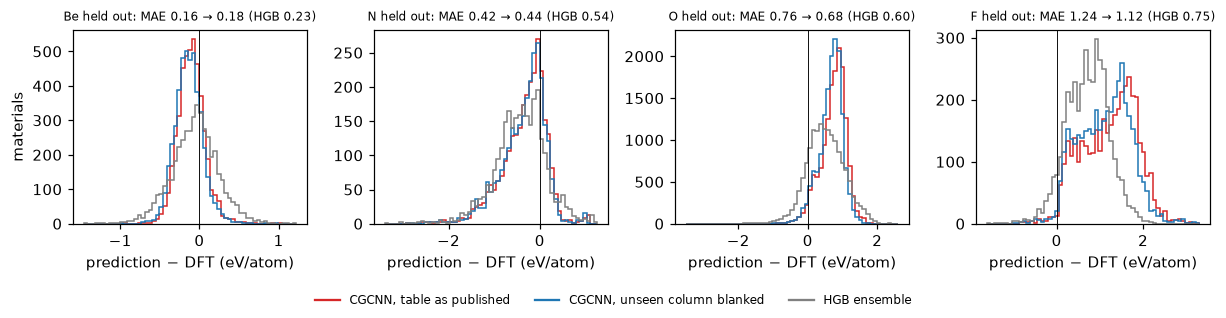

In [17]:
if blank_rows:
    fig, axes = plt.subplots(1, len(blank_rows), figsize=(2.8 * len(blank_rows), 2.9), squeeze=False)
    series = (("CGCNN, table as published", "C3"), ("CGCNN, unseen column blanked", "C0"), ("HGB ensemble", "0.5"))
    for ax, row in zip(axes[0], blank_rows, strict=True):
        r = R[f"element-{row['element']}"]
        y = r["y_test"]
        errors = [r["test_mu_cg"] - y, row["pred_blanked"] - y, r["test_mu_ens"] - y]
        bins = np.linspace(min(e.min() for e in errors), max(e.max() for e in errors), 60)
        for err, (label, color) in zip(errors, series, strict=True):
            ax.hist(err, bins=bins, histtype="step", color=color, lw=1.0, label=label)
        ax.axvline(0, color="k", lw=0.6)
        ax.set_title(f"{row['element']} held out: MAE {row['mae']:.2f} → {row['mae_blanked']:.2f} (HGB {row['mae_hgb']:.2f})",
                     fontsize=8)
        ax.set_xlabel("prediction − DFT (eV/atom)")
    axes[0][0].set_ylabel("materials")
    handles = [plt.Line2D([], [], color=c, label=lab) for lab, c in series]
    fig.legend(handles=handles, frameon=False, fontsize=8, ncol=3, loc="lower center")
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    fig.savefig("figures/unseen_columns.png")
    plt.show()

## 5. Does the CGCNN ensemble know when it is wrong?

The standard deviation of the five CGCNNs is used as an uncertainty, as the spread of the five gradient-boosting models (HGB) and the deep ensemble (MLP) were in the `uncertainty` experiment, and evaluated with its measures on the same tasks:

- **ranking**: Spearman correlation between the standard deviation and the absolute error, pooled over the tasks of a split and as the median over its tasks (for leave one element out the pooled number mixes elements of different difficulty);
- **conformal 90 % intervals** from the task's calibration set, with constant width (residual scores) and with width proportional to the standard deviation (normalized scores): coverage and median width;
- **calibration** of the standard deviation as a Gaussian one: the fraction inside the central 90 % Gaussian interval, raw and after std scaling with the factor fitted on the calibration set.

The five CGCNNs differ only in their initial weights and the order of the batches; they are not trained on bootstrap samples and do not predict a variance.

In [18]:
UQ_METHODS = {"CGCNN ensemble": ("mu_cg", "sd_cg"), "HGB ensemble": ("mu_ens", "sd_ens"),
              "random forest": ("mu_rf", "sd_rf"), "MLP deep ensemble": ("mu_nn", "sd_nn")}
z90 = stats.norm.ppf(1 - ALPHA / 2)


def task_metrics(r, mu_key, sd_key):
    mu, sd, y = r[f"test_{mu_key}"], r[f"test_{sd_key}"], r["y_test"]
    err = np.abs(mu - y)
    out = {"spearman": uq.spearman(sd, err)}
    for name, s_cal, s_test in (("residual", None, None), ("normalized", r[f"cal_{sd_key}"], sd)):
        lo, hi = uq.conformal_interval(mu, uq.residual_scores(r["y_cal"], r[f"cal_{mu_key}"], s_cal), ALPHA, scale=s_test)
        out[f"cover_{name}"] = uq.interval_coverage(y, lo, hi)
        out[f"width_{name}"] = float(np.median(hi - lo))
    factor = uq.std_scale(r["y_cal"], r[f"cal_{mu_key}"], r[f"cal_{sd_key}"])
    out["inside90_raw"] = float(np.mean(err <= z90 * sd))
    out["inside90_scaled"] = float(np.mean(err <= z90 * factor * sd))
    out["factor"] = factor
    return out


uq_table = defaultdict(dict)
cols = ["spearman pooled", "spearman median", "cover_residual", "cover_normalized", "width_normalized",
        "inside90_raw", "inside90_scaled", "factor"]
print(f"{'split':24s} {'method':18s} " + " ".join(f"{c:>17s}" for c in cols))
for split in SPLITS:
    rs = [r for r in R.values() if r["split"] == split]
    if not rs:
        continue
    for name, (mu_key, sd_key) in UQ_METHODS.items():
        per = [task_metrics(r, mu_key, sd_key) for r in rs]
        err = np.concatenate([np.abs(r[f"test_{mu_key}"] - r["y_test"]) for r in rs])
        sd = np.concatenate([r[f"test_{sd_key}"] for r in rs])
        row = {"spearman pooled": uq.spearman(sd, err), "spearman median": float(np.median([p["spearman"] for p in per]))}
        for c in cols[2:]:
            vals = np.array([p[c] for p in per])
            row[c] = float(np.median(vals)) if c == "factor" else float(np.mean(vals))
        row["cover_range"] = (min(p["cover_normalized"] for p in per), max(p["cover_normalized"] for p in per))
        uq_table[split][name] = row
        print(f"{split:24s} {name:18s} " + " ".join(f"{row[c]:17.3f}" for c in cols))

split                    method               spearman pooled   spearman median    cover_residual  cover_normalized  width_normalized      inside90_raw   inside90_scaled            factor
random                   CGCNN ensemble                 0.341             0.342             0.902             0.897             0.221             0.675             0.924             2.342
random                   HGB ensemble                   0.544             0.544             0.899             0.899             0.315             0.678             0.932             2.536
random                   random forest                  0.644             0.643             0.901             0.901             0.338             0.985             0.926             0.587
random                   MLP deep ensemble              0.566             0.564             0.898             0.899             0.318             0.933             0.922             0.946
chemical-system groups   CGCNN ensemble                 0.36

prototype groups         CGCNN ensemble                 0.416             0.403             0.895             0.898             0.308             0.630             0.923             2.521
prototype groups         HGB ensemble                   0.453             0.456             0.887             0.892             0.604             0.505             0.919             3.801
prototype groups         random forest                  0.600             0.595             0.886             0.898             0.645             0.952             0.923             0.818
prototype groups         MLP deep ensemble              0.470             0.471             0.892             0.894             0.717             0.871             0.906             1.118
leave one element out    CGCNN ensemble                 0.643             0.458             0.377             0.810             1.145             0.511             0.855             2.410
leave one element out    HGB ensemble                   0.38

prospective              random forest                  0.609             0.609             0.877             0.878             0.411             0.981             0.893             0.548
prospective              MLP deep ensemble              0.533             0.533             0.871             0.856             0.339             0.882             0.894             1.045


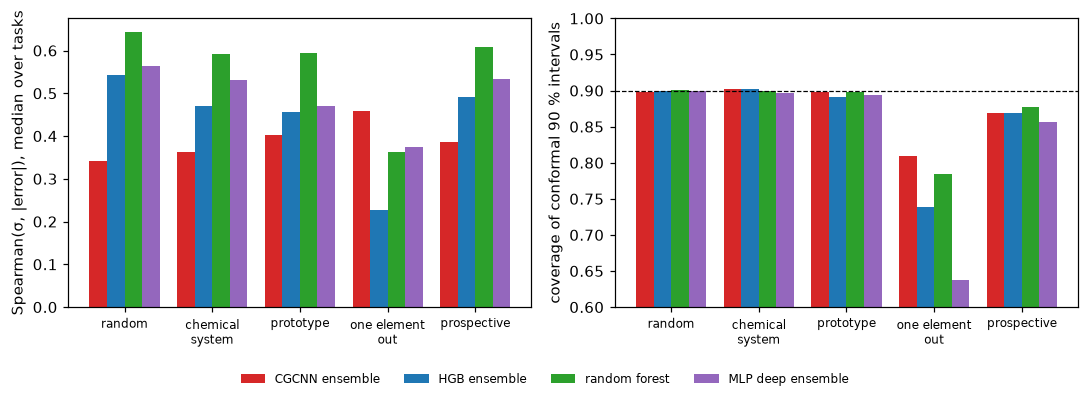

In [19]:
if uq_table:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    present = [s for s in SPLITS if s in uq_table]
    x = np.arange(len(present))
    for j, (name, color) in enumerate(zip(UQ_METHODS, ("C3", "C0", "C2", "C4"), strict=True)):
        axes[0].bar(x + (j - 1.5) * 0.2, [uq_table[s][name]["spearman median"] for s in present], width=0.2,
                    color=color, label=name)
        axes[1].bar(x + (j - 1.5) * 0.2, [uq_table[s][name]["cover_normalized"] for s in present], width=0.2,
                    color=color)
    axes[1].axhline(1 - ALPHA, color="k", lw=0.8, ls="--")
    axes[0].set_ylabel("Spearman(σ, |error|), median over tasks")
    axes[1].set_ylabel("coverage of conformal 90 % intervals")
    axes[1].set_ylim(0.6, 1.0)
    for ax in axes:
        ax.set_xticks(x, [s.replace(" groups", "").replace("chemical-system", "chemical\nsystem")
                          .replace("leave one element out", "one element\nout") for s in present], fontsize=8)
    fig.legend(frameon=False, fontsize=8, ncol=4, loc="lower center")
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.savefig("figures/uncertainty.png")
    plt.show()

### The confidently wrong structure type

In the `uncertainty` experiment one structure type of the prototype split, the largest-error type with at least 500 materials, was predicted with errors of about 0.5 eV/atom by every descriptor model, while the deep ensemble and quantile regression rated those predictions as more certain than a typical one. Does CGCNN, which sees the structure itself, do better on it, and does its ensemble notice?

In [20]:
proto = [r for r in R.values() if r["split"] == "prototype groups"]
if len(proto) == 10:
    idx = np.concatenate([r["test"] for r in proto])
    y = np.concatenate([r["y_test"] for r in proto])
    labels = np.array(d["proto"])[idx]
    err_hgb = np.abs(np.concatenate([r["test_mu_ens"] for r in proto]) - y)
    big = [g for g, c in Counter(labels).items() if c >= 500]
    worst = max(big, key=lambda g: err_hgb[labels == g].mean())
    m = labels == worst
    print(f"structure type {worst}: {m.sum()} materials")
    print(f"  {'method':18s} {'MAE on this type':>17s} {'MAE on the other types':>23s} {'median uncertainty percentile':>30s}")
    for name, (mu_key, sd_key) in UQ_METHODS.items():
        e = np.abs(np.concatenate([r[f"test_{mu_key}"] for r in proto]) - y)
        u = np.concatenate([r[f"test_{sd_key}"] for r in proto])
        pct = stats.rankdata(u)[m] / len(u)
        print(f"  {name:18s} {e[m].mean():17.3f} {e[~m].mean():23.3f} {np.median(pct):30.2f}")

structure type (216, ((1, ('a',)), (1, ('c',)), (4, ('e',)))): 1402 materials
  method              MAE on this type  MAE on the other types  median uncertainty percentile
  CGCNN ensemble                 0.319                   0.078                           0.89
  HGB ensemble                   0.651                   0.144                           0.69
  random forest                  0.641                   0.170                           0.83
  MLP deep ensemble              0.514                   0.183                           0.22


## 6. Summary

In [21]:
print(f"{'quantity':66s} {'this run':>18s} {'check':>26s}  from")
for q, v, c, src in summary:
    print(f"{q:66s} {v:>18s} {c:>26s}  {src}")

quantity                                                                     this run                      check  from
same weights as the original code, train mode: largest output difference              2e-07   0 up to float32 rounding  txie-93/cgcnn f42ab23
same weights as the original code, eval mode: largest output difference              2e-06   0 up to float32 rounding  txie-93/cgcnn f42ab23
neighbor lists identical to the original construction                     2000 / 2000                2000 / 2000  Structure.get_all_neighbors + sort
test MAE, leaderboard split, single network (5 seeds)                 0.0641 ± 0.0012                     0.0625  JARVIS leaderboard, CGCNN entry
test MAE, leaderboard split, ensemble of 5                                     0.0548                      0.063  Choudhary & DeCost 2021, Table 3
leave one element out, Spearman of R2 over 12 elements                           0.96      ALIGNN R2 per element  Li et al. 2024, Suppl. Fig. 3
leave Be out

In [22]:
export = {
    "about": "CGCNN (Xie & Grossman 2018) re-implemented from the released code; JARVIS-DFT formation energy",
    "leaderboard": {"single_mae": single.tolist() if lb else [], "ensemble_mae": float(ens_mae) if lb else None,
                    "leaderboard_mae": float(board_mae), "budgets": budget_rows},
    "mae": mae_table,
    "elements": [dict(zip(("element", "n", "mae_cgcnn", "mae_hgb", "r2_cgcnn", "r2_hgb", "r2_xgb_li2024",
                           "r2_alignn_li2024", "bias_cgcnn"), row, strict=True)) for row in el_rows],
    "uncertainty": {s: {m: {k: v for k, v in row.items() if k != "cover_range"} for m, row in t.items()}
                    for s, t in uq_table.items()},
    "unseen_columns": {e: [int(c) for c in cols] for e, cols in unseen.items()},
    "blanked": [{k: v for k, v in row.items() if k != "pred_blanked"} for row in blank_rows],
    "settings": runs.SETTINGS,
}
with open("cgcnn_results.json", "w", encoding="utf-8") as f:
    json.dump(export, f, indent=1, default=float)
print("written cgcnn_results.json")

written cgcnn_results.json


## Discussion

**The re-implementation is the original.** With the same weights it gives the outputs of the authors' code to within float32 rounding (the pooling sums in another order), and its neighbor lists are those of the authors' construction in 2000 of 2000 structures. Five networks trained like the leaderboard's reach a test MAE of 0.0641 ± 0.0012 eV/atom against the leaderboard's 0.0625. The leaderboard's network is better than each of the five, by 0.0002 to 0.0031 eV/atom (for seed 0 the paired bootstrap interval excludes zero), but its errors correlate with those of seed 0 as strongly as the errors of two of our seeds do with each other (0.749 against 0.743): it behaves like one more seed of the same network. The change of normalizer (500 training materials instead of 500 of the whole data set) and the variation between runs are the candidates for the remaining 2.5 %; which one it is was not resolved. The ensemble of the five reaches 0.0548.

**Where the elements are known, CGCNN is better and loses less under shift.** Trained on the same materials, the CGCNN ensemble beats the gradient-boosting ensemble of the `uncertainty` experiment on every fold of the random, chemical-system and prototype splits and on the prospective test, with 36 % (random), 41 % (chemical systems), 47 % (prototypes) and 37 % (prospective) lower MAE; even a single CGCNN has a lower mean MAE than the gradient-boosting ensemble on all four. It also loses less under the shift: on new structure types its MAE is 1.49 times its random-split MAE (gradient boosting 1.79), on new chemical systems 1.10 times (1.20), on the materials added after 2021 about the same (1.30 against 1.33). Reading the structure helps most where the structure is new.

**Unseen elements are the exception.** With an element held out, the CGCNN ensemble is worse than gradient boosting on 10 of the 12 elements, and its mean MAE is 6.8 times its random-split MAE (gradient boosting 3.45). Its R² ranks the 12 elements almost as ALIGNN's does in Li et al. (Spearman 0.96) and as gradient boosting's (0.95): the same elements are hard for every model, and the graph network fails harder on them. Fluorine is the extreme: the ensemble overestimates the formation energy of fluorides by 1.23 eV/atom on average (R² −1.30; ALIGNN −0.76 and XGBoost −0.21 in Li et al.).

**An explanation that was tested and mostly rejected.** Four of the 12 elements have an atom-feature column that no training material has (F and O: the two highest electronegativity bins; N and Be: two electron-affinity bins), so its weights stay random. Setting that column to zero for the held-out element removes the random contribution and leaves the training untouched (the validation MAE agrees to 2 × 10⁻⁸ eV/atom). The MAE of fluorides falls from 1.24 to 1.12 eV/atom and that of oxides from 0.76 to 0.68, but both stay above gradient boosting (0.75 and 0.60) and the bias of fluorides stays at +1.11 eV/atom; for Be and N the MAE rises slightly (0.16 to 0.18 and 0.42 to 0.44). The untrained weights thus account for about a tenth of the error on F and O and none on N and Be. The failure on the most electronegative elements is mostly something else, in line with Li et al., who traced the bias of XGBoost on these elements to composition rather than structure. ALIGNN's default atom features are the same table, so the same small contribution is possible there; that was not tested.

**The spread of the five networks ranks errors poorly in distribution and best under the hardest shift.** The five CGCNNs differ only in their initial weights and the order of the batches. On the random, chemical-system, prototype and prospective test sets their spread ranks the errors worse than every uncertainty of the descriptor models (median Spearman 0.34–0.40 against 0.46–0.64), and it is 2.3–2.7 times too small, like the bootstrap ensemble's (2.5–3.8). With an element held out the order reverses: within the compounds of one element it ranks best (median 0.46 against 0.23–0.38), and conformal intervals scaled by it keep the most coverage (0.81 against 0.64–0.78, mean over the 12 elements). Intervals of constant width do the opposite: CGCNN is so accurate on the calibration materials that its constant-width intervals are narrow, and they cover only 0.38 of the compounds of an unseen element (gradient boosting 0.60). On the structure type that every descriptor model predicted badly in the `uncertainty` experiment, CGCNN halves the error (0.32 against 0.65 eV/atom) and puts its uncertainty at the 89th percentile, where the deep ensemble put it at the 22nd.

**Caveats.** The shift networks were trained for 150 epochs instead of 300, and more than half of them reached their best validation MAE in the last 10 epochs: they were still improving. On the first prototype fold the 300-epoch network was 6.5 % better than the 150-epoch one (1.7 % on the first chemical-system fold, none for F), so CGCNN's advantage on the known-element splits is if anything understated. Leave one element out covers 12 of the 78 elements, chosen to include the six hardest, so its means are not those of the `uncertainty` experiment over all 78. Each task has one assignment of materials, and the spread between seeds is the only replication.

For compounds of an element absent from training, a graph network that has to learn every element from the training data is worse than gradient boosting on element descriptors, and changing the input table does not fix that. Pretrained universal models have seen every element during pretraining; whether their representations close this gap is the question of the `pretrained_features` experiment.